# LAB: Feature Engineering 🔧⚡

**Goal:** turn raw energy time series into useful, defensible features — and explain *why* each feature exists.

This practical is intentionally different from a step-by-step tutorial. You will:

- ✏️ **complete small pieces of code** rather than write everything from scratch,
- 💬 **answer short interpretation questions**,
- 🧪 **change parameters and observe what happens**,
- 🎛️ use a few **interactive widgets**,
- 🤖 use an **LLM as a feature-idea generator**, then verify its suggestions yourself.

### Learning outcomes
By the end, you should be able to distinguish and apply:

1. **feature creation**,
2. **scaling**,
3. **transformation**,
4. **feature extraction** (conceptually),
5. **feature selection**,

and detect a particularly dangerous energy-forecasting problem: **data leakage**.

> **Working rule:** a feature is useful only if it is meaningful **and available at prediction time**.


In [1]:
# Core imports
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_regression
from IPython.display import display, Markdown

# Interactive widgets
try:
    import ipywidgets as widgets
    from ipywidgets import interact
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print("ipywidgets is not installed. The core exercises still work, but interactive cells will be skipped.")


def TODO(message="Complete this line"):
    raise NotImplementedError("TODO: " + message)


def nrmse(y_true, y_pred):
    """NRMSE (%) = RMSE / (max(y_true) - min(y_true)) * 100.

    Normalisation uses the observed target range in the evaluation set.
    Lower values indicate better predictions.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    target_range = y_true.max() - y_true.min()
    if target_range <= 0:
        raise ValueError("NRMSE is undefined when the evaluation target has zero range.")
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return 100 * rmse / target_range


pd.set_option("display.max_columns", 30)


---
# 1. Load the energy data ⚡

Both CSV files are read **directly from GitHub** at runtime; nothing is saved locally. An internet connection is required.


In [4]:
# Read directly from GitHub (no local files or downloads)
ENERGY_URL = (
    'https://raw.githubusercontent.com/drmatson/energy_informatics/main/data/'
    'electricity-production%20and%20consumption_2022.csv'
)
elering = pd.read_csv(ENERGY_URL, sep=';', decimal=',')

# The source uses day.month.year hour:minute in Estonian local time.
elering['timestamp'] = pd.to_datetime(
    elering['Kuupaev (Eesti aeg)'].str.strip(),
    format='%d.%m.%Y %H:%M',
    errors='raise'
)
elering = elering.set_index('timestamp').sort_index()
demand = elering[['Tarbimine']].rename(columns={'Tarbimine': 'demand'}).copy()

print('Demand:', demand.shape, '| first:', demand.index.min(), '| last:', demand.index.max())
display(demand.head())


Demand: (8760, 1) | first: 2022-01-01 00:00:00 | last: 2022-12-31 23:00:00


,demand
timestamp,
2022-01-01 00:00:00,899.4
2022-01-01 01:00:00,892.1
2022-01-01 02:00:00,874.3
2022-01-01 03:00:00,860.1
2022-01-01 04:00:00,842.7


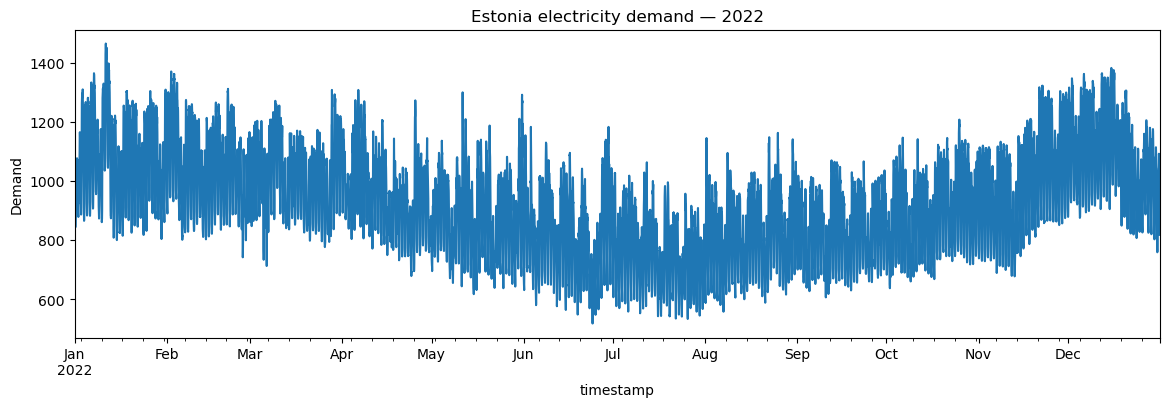

In [5]:
# Quick visual check
ax = demand['demand'].plot(figsize=(14, 4), title='Estonia electricity demand — 2022')
ax.set_ylabel('Demand')
plt.show()

### 💬 Observe — suggested answer
Likely patterns include:

1. **daily/diurnal cycle** (night vs morning/evening activity),
2. **weekly cycle** (working days vs weekends).

Seasonal effects may also appear across the year.


---
# 2. Feature creation — calendar features 📅

Complete only the missing pieces. Do not rewrite the whole cell.


In [6]:
# ✅ Solution — calendar features

demand['hour'] = demand.index.hour
demand['weekday'] = demand.index.dayofweek
demand['is_weekend'] = (demand['weekday'] >= 5).astype(int)

display(demand[['demand', 'hour', 'weekday', 'is_weekend']].head(30))

,demand,hour,weekday,is_weekend
timestamp,,,,
2022-01-01 00:00:00,899.4,0,5,1
2022-01-01 01:00:00,892.1,1,5,1
2022-01-01 02:00:00,874.3,2,5,1
2022-01-01 03:00:00,860.1,3,5,1
2022-01-01 04:00:00,842.7,4,5,1
2022-01-01 05:00:00,844.7,5,5,1
2022-01-01 06:00:00,852.2,6,5,1
2022-01-01 07:00:00,868.4,7,5,1
2022-01-01 08:00:00,874.8,8,5,1


### 💬 Question — suggested answer
The numeric representation makes 23 and 0 look far apart although they are adjacent in time. Sine/cosine encoding places hours on a circle, preserving periodic proximity.


## 2.1 Cyclical encoding ⏰

Complete the periods in the sine/cosine formulas.


In [7]:
# ✅ Solution — cyclical features
HOURS_IN_CYCLE = 24
DAYS_IN_WEEK = 7

demand['hour_sin'] = np.sin(2 * np.pi * demand['hour'] / HOURS_IN_CYCLE)
demand['hour_cos'] = np.cos(2 * np.pi * demand['hour'] / HOURS_IN_CYCLE)
demand['weekday_sin'] = np.sin(2 * np.pi * demand['weekday'] / DAYS_IN_WEEK)
demand['weekday_cos'] = np.cos(2 * np.pi * demand['weekday'] / DAYS_IN_WEEK)

display(demand[['hour', 'hour_sin', 'hour_cos', 'weekday', 'weekday_sin', 'weekday_cos']].head())

,hour,hour_sin,hour_cos,weekday,weekday_sin,weekday_cos
timestamp,,,,,,
2022-01-01 00:00:00,0,0.000000,1.000000,5,-0.974928,-0.222521
2022-01-01 01:00:00,1,0.258819,0.965926,5,-0.974928,-0.222521
2022-01-01 02:00:00,2,0.500000,0.866025,5,-0.974928,-0.222521
2022-01-01 03:00:00,3,0.707107,0.707107,5,-0.974928,-0.222521
2022-01-01 04:00:00,4,0.866025,0.500000,5,-0.974928,-0.222521


### 🎛️ Interactive: raw distance vs cyclical distance
Move the two sliders. Try **23 and 0**, then **12 and 0**.


In [8]:
def compare_hour_distance(h1=23, h2=0):
    raw_distance = abs(h1 - h2)

    p1 = np.array([
        np.sin(2*np.pi*h1/24),
        np.cos(2*np.pi*h1/24)
    ])
    p2 = np.array([
        np.sin(2*np.pi*h2/24),
        np.cos(2*np.pi*h2/24)
    ])
    cyclical_distance = np.linalg.norm(p1 - p2)

    print(f"Raw hour distance:      {raw_distance:.2f}")
    print(f"Cyclical 2D distance:   {cyclical_distance:.3f}")

if WIDGETS_AVAILABLE:
    interact(
        compare_hour_distance,
        h1=widgets.IntSlider(min=0, max=23, value=23, description='hour A'),
        h2=widgets.IntSlider(min=0, max=23, value=0, description='hour B')
    )
else:
    compare_hour_distance(23, 0)

interactive(children=(IntSlider(value=23, description='hour A', max=23), IntSlider(value=0, description='hour …

### 💬 Interpret — suggested answer
It makes the representation periodic: 23:00 and 00:00 become close in feature space, while opposite times of day remain far apart.


---
# 3. Leakage detective 🕵️‍♀️

Feature engineering is not just about inventing columns. A feature can look highly predictive because it accidentally contains the answer.

Assume the target is demand at time **t**.


In [9]:
mcq(
    "Which rolling feature is SAFE for predicting demand at time t?",
    [
        "demand.rolling(24).mean()",
        "demand.shift(1).rolling(24).mean()",
        "demand.shift(-1).rolling(24).mean()"
    ],
    "demand.shift(1).rolling(24).mean()",
    "The window must end at t-1, not include the target at t or any future value."
)

**Which rolling feature is SAFE for predicting demand at time t?**

RadioButtons(options=('demand.rolling(24).mean()', 'demand.shift(1).rolling(24).mean()', 'demand.shift(-1).rol…

Button(description='Check', style=ButtonStyle())

Output()

## 3.1 Create safe lag and rolling features

The previous tutorial created lags and rolling statistics. Here, make the rolling feature explicitly **leakage-safe**.


In [10]:
# ✅ Solution — safe lags and rolling features

demand['lag1'] = demand['demand'].shift(1)
demand['lag24'] = demand['demand'].shift(24)
demand['lag168'] = demand['demand'].shift(168)

past_demand = demand['demand'].shift(1)
demand['roll_mean_24h_safe'] = past_demand.rolling(24).mean()
demand['roll_std_24h_safe'] = past_demand.rolling(24).std()

display(demand[['demand', 'lag1', 'lag24', 'lag168', 'roll_mean_24h_safe']].head(175).tail(10))

,demand,lag1,lag24,lag168,roll_mean_24h_safe
timestamp,,,,,
2022-01-07 21:00:00,1163.3,1223.3,1164.6,NaN,1171.879167
2022-01-07 22:00:00,1104.9,1163.3,1090.6,NaN,1171.825000
2022-01-07 23:00:00,1039.8,1104.9,1018.1,NaN,1172.420833
2022-01-08 00:00:00,1004.3,1039.8,955.7,899.4,1173.325000
2022-01-08 01:00:00,982.6,1004.3,929.1,892.1,1175.350000
2022-01-08 02:00:00,962.7,982.6,918.8,874.3,1177.579167
2022-01-08 03:00:00,960.8,962.7,906.4,860.1,1179.408333
2022-01-08 04:00:00,955.1,960.8,908.0,842.7,1181.675000
2022-01-08 05:00:00,963.3,955.1,940.1,844.7,1183.637500


### 💬 Leakage check — suggested answer
Because the rolling window includes the current value `demand[t]`, which is also the target being predicted. The model therefore receives part of the answer. Shifting by one step before rolling makes the window end at `t-1`.


---
# 4. External + domain-specific features 🌦️🔥

Weather data also comes directly from GitHub. Dates are parsed explicitly as `DD.MM.YYYY HH:MM`; duplicate local timestamps at the autumn DST transition are averaged for the weather join.


In [11]:
# Read weather directly from GitHub — do not save a local copy.
WEATHER_URL = (
    'https://raw.githubusercontent.com/drmatson/energy_informatics/main/data/'
    'weather_2022.csv'
)
weather = pd.read_csv(WEATHER_URL, sep=';', decimal='.', index_col=False, low_memory=False)

# Explicitly parse DD.MM.YYYY HH:MM; source rows are newest-first.
weather['timestamp'] = pd.to_datetime(
    weather['Local time in Tallinn (airport)'].astype(str).str.strip(),
    format='%d.%m.%Y %H:%M',
    errors='raise'
)

# Some columns mix measurements and text: coerce only the fields we need.
weather_cols = ['T'] + (['ff3'] if 'ff3' in weather.columns else [])
for col in weather_cols:
    weather[col] = pd.to_numeric(weather[col], errors='coerce')

weather_small = weather.set_index('timestamp')[weather_cols].sort_index()

# DST (autumn): local timestamps may repeat. Combine duplicate weather
# measurements so a join never multiplies the number of demand rows.
if weather_small.index.has_duplicates:
    print('Repeated local weather timestamps:', weather_small.index.duplicated().sum())
    weather_small = weather_small.groupby(level=0).mean()

weather_small = weather_small.rename(columns={
    'T': 'temperature', 'ff3': 'wind_speed'
})
demand = demand.join(weather_small, how='left', validate='many_to_one')

print('Weather dates:', weather_small.index.min(), 'to', weather_small.index.max())
print('Demand rows after join:', len(demand))
print('Missing temperature:', demand['temperature'].isna().sum())
display(demand[['demand', 'temperature']].head())


Repeated local weather timestamps: 1
Weather dates: 2022-01-01 00:00:00 to 2022-12-31 23:00:00
Demand rows after join: 8760
Missing temperature: 29


,demand,temperature
timestamp,,
2022-01-01 00:00:00,899.4,-1.0
2022-01-01 01:00:00,892.1,-0.6
2022-01-01 02:00:00,874.3,0.0
2022-01-01 03:00:00,860.1,-0.1
2022-01-01 04:00:00,842.7,-0.1


## 4.1 Heating degree feature

A simple domain feature is **heating degree** relative to a base temperature:

$$
HDD_t = \max(0, T_{base} - T_t)
$$

For this exercise, use **18°C** as the base.


In [12]:
# ✅ Solution — heating degree
BASE_TEMPERATURE = 18
demand['heating_degree'] = np.maximum(BASE_TEMPERATURE - demand['temperature'], 0)

display(demand[['temperature', 'heating_degree']].dropna().head(20))

,temperature,heating_degree
timestamp,,
2022-01-01 00:00:00,-1.0,19.0
2022-01-01 01:00:00,-0.6,18.6
2022-01-01 02:00:00,0.0,18.0
2022-01-01 03:00:00,-0.1,18.1
2022-01-01 04:00:00,-0.1,18.1
2022-01-01 05:00:00,-0.3,18.3
2022-01-01 06:00:00,-0.4,18.4
2022-01-01 07:00:00,-0.4,18.4
2022-01-01 08:00:00,-1.3,19.3


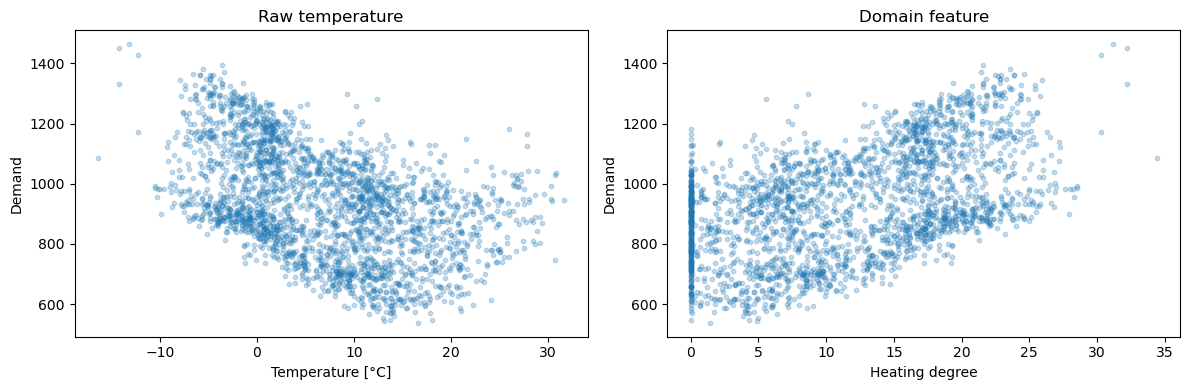

In [13]:
# Explore the relationship
sample = demand[['demand', 'temperature', 'heating_degree']].dropna().sample(
    min(2500, demand[['demand', 'temperature', 'heating_degree']].dropna().shape[0]),
    random_state=42
)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(sample['temperature'], sample['demand'], alpha=0.25, s=10)
ax[0].set_xlabel('Temperature [°C]')
ax[0].set_ylabel('Demand')
ax[0].set_title('Raw temperature')

ax[1].scatter(sample['heating_degree'], sample['demand'], alpha=0.25, s=10)
ax[1].set_xlabel('Heating degree')
ax[1].set_ylabel('Demand')
ax[1].set_title('Domain feature')
plt.tight_layout()
plt.show()

### 💬 Think like a modeller — suggested answer
✅ **NO.** Historical measured temperature is fine for retrospective analysis, but an operational forecast for a future timestamp must use weather information that would have been available at the forecast origin, typically a weather forecast.


---
# 5. Transformation vs scaling 🔄⚖️

These are different operations:

- **Transformation** can change the *shape* of a distribution.
- **Scaling** changes the *scale/units* but usually preserves its shape.

Use the interactive control below to inspect a deliberately right-skewed energy-price-like variable.


In [14]:
# Single-image interactive widget: update PNG bytes, never append plot outputs.
# This avoids repeated Matplotlib plots in VS Code/Jupyter.
from io import BytesIO
from IPython.display import Image

rng = np.random.default_rng(42)
price_demo = rng.lognormal(mean=4.0, sigma=0.9, size=3000)

def show_transform(kind='raw'):
    x = price_demo.copy()

    if kind == 'log1p':
        x = np.log1p(x)
    elif kind == 'sqrt':
        x = np.sqrt(x)
    elif kind == 'standardized':
        x = (x - x.mean()) / x.std()

    skewness = pd.Series(x).skew()
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.hist(x, bins=40)
    ax.set_title(f'{kind} | skewness = {skewness:.2f}')
    ax.set_xlabel('value')
    ax.set_ylabel('count')

    # Convert plot to PNG in memory. Close BEFORE displaying anything.
    buffer = BytesIO()
    fig.savefig(buffer, format='png', bbox_inches='tight')
    plt.close(fig)
    png_data = buffer.getvalue()
    buffer.close()
    return png_data

if WIDGETS_AVAILABLE:
    transform_selector = widgets.Dropdown(
        options=['raw', 'log1p', 'sqrt', 'standardized'],
        value='raw',
        description='kind'
    )
    # Exactly one image widget exists; changing selection replaces its contents.
    transform_image = widgets.Image(
        value=show_transform('raw'),
        format='png'
    )

    def update_transform(change):
        transform_image.value = show_transform(change['new'])

    transform_selector.observe(update_transform, names='value')
    display(widgets.VBox([transform_selector, transform_image]))
else:
    display(Image(data=show_transform('raw')))


### 💬 Questions — suggested answer
1. For this synthetic sample, **log1p** should reduce the right-skew most strongly (students should verify from the displayed skewness).  
2. Standardisation is a linear rescaling: it changes mean and variance, but it does not fundamentally change the distribution's shape/skewness.


## 5.1 Experiment A — KNN: when scaling makes a big difference 🧪

First, create a **controlled synthetic regression problem** (not a time series). The target depends on one informative feature, `useful_signal` (values between 0 and 1). A second feature, `irrelevant_noise`, is unrelated to the target.

KNN uses **distances** between rows. If the irrelevant feature has a much larger numerical range, it can dominate those distances — even though it predicts nothing.

**Try it yourself:**

1. ✏️ Complete the missing preprocessing step (`StandardScaler`) in the pipeline below.
2. 🎛️ Change **Noise scale** from `1` to `8,000` and compare NRMSE for the **same KNN** with and without scaling.
3. 💬 Explain why increasing the numerical magnitude of a useless column harms one version but not the other.

The train/test split, random seed, number of neighbors, and target values remain the **same** throughout. The scaler is fitted **only on training data** through the pipeline.


In [15]:
# KNN scaling demo: one persistent image widget (no repeated plots).
from io import BytesIO
from IPython.display import Image

# Reproducible synthetic data: target depends ONLY on useful_signal
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

rng_knn = np.random.default_rng(42)
n_demo = 1400
useful_signal = rng_knn.uniform(0, 1, n_demo)
irrelevant_noise = rng_knn.uniform(0, 1, n_demo)
y_demo = 10 + 5 * np.sin(2 * np.pi * useful_signal) + rng_knn.normal(0, 0.15, n_demo)


def compare_knn(noise_multiplier=8000):
    X_demo = pd.DataFrame({
        'useful_signal': useful_signal,
        'irrelevant_noise': irrelevant_noise * noise_multiplier
    })

    # IID synthetic data (not a time-series experiment): random split is appropriate here.
    X_train_demo, X_test_demo, y_train_demo, y_test_demo = train_test_split(
        X_demo, y_demo, test_size=0.30, random_state=42
    )

    knn_raw = KNeighborsRegressor(n_neighbors=7, weights='distance')
    knn_raw.fit(X_train_demo, y_train_demo)
    raw_score = nrmse(y_test_demo, knn_raw.predict(X_test_demo))

    # ✏️ TODO 6a — supply the missing preprocessing step for KNN
    knn_scaled = make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=7, weights='distance')
    )
    knn_scaled.fit(X_train_demo, y_train_demo)
    scaled_score = nrmse(y_test_demo, knn_scaled.predict(X_test_demo))

    # Render a PNG in memory; never send a live Matplotlib Figure to Jupyter.
    fig, ax = plt.subplots(figsize=(6.5, 3))
    ax.bar(['No scaling', 'StandardScaler'], [raw_score, scaled_score],
           color=['tab:orange', 'tab:blue'])
    ax.set_ylabel('NRMSE (%) — lower is better')
    ax.set_ylim(bottom=0)
    ax.set_title(f'KNN: scaling irrelevant_noise by {noise_multiplier:,}')

    with BytesIO() as buffer:
        fig.savefig(buffer, format='png', bbox_inches='tight')
        image_bytes = buffer.getvalue()
    plt.close(fig)  # prevent automatic display by the inline Matplotlib backend
    return raw_score, scaled_score, image_bytes


if WIDGETS_AVAILABLE:
    noise_slider = widgets.SelectionSlider(
        options=[1, 10, 100, 1000, 8000],
        value=8000,
        description='Noise scale',
        continuous_update=False,
        style={'description_width': 'initial'},
    )
    knn_image = widgets.Image(format='png')
    knn_results = widgets.HTML()

    def update_knn(change=None):
        try:
            raw_score, scaled_score, png = compare_knn(noise_slider.value)
        except NotImplementedError:
            # Expected until students complete TODO 6a.
            knn_results.value = 'Complete <code>TODO 6a</code>, then rerun this cell.'
            knn_image.value = b''
            return
        knn_results.value = (
            f'Noise scale: x{noise_slider.value:,} &nbsp;|&nbsp; '
            f'KNN without scaling: <b>{raw_score:.2f}%</b> &nbsp;|&nbsp; '
            f'KNN with scaling: <b>{scaled_score:.2f}%</b>'
        )
        knn_image.value = png  # update SAME image, not a new figure/output

    noise_slider.observe(update_knn, names='value')
    update_knn()
    display(widgets.VBox([noise_slider, knn_results, knn_image]))
else:
    raw_score, scaled_score, png = compare_knn(noise_multiplier=8000)
    print(f'KNN without scaling — NRMSE: {raw_score:.2f}%')
    print(f'KNN with scaling    — NRMSE: {scaled_score:.2f}%')
    display(Image(data=png))


### 💬 KNN — suggested answers

1. **Yes.** At scale `1`, both features are already on comparable scales: NRMSE is approximately **2.7%** for either approach.
2. **StandardScaler wins decisively.** With `8,000`, unscaled KNN's NRMSE is approximately **36.9%**, compared with **2.7%** after scaling. The irrelevant column overwhelms Euclidean distances without scaling. Exact numbers can vary slightly by package version.
3. **No.** This is a deliberately constructed case, not a universal law. Scaling equalizes the units of features, **not their relevance**. On another real dataset, it may produce a small improvement, no improvement, or worse NRMSE. Model evaluation decides.

**Instructor prompt:** Ask what would happen if we *removed* the irrelevant column entirely; scaling is not the same as feature selection.


## 5.2 Experiment B — Random Forest on real electricity demand 🌲⚡

Now use the **real energy dataset** to compare a tree-based model with and without scaling. Random Forest splits values using thresholds, so standardising numeric features usually does **not** change the trees' partitions or materially improve NRMSE.

✏️ Complete **TODO 6b**. Use an identical **chronological 80/20 split**, feature set, hyperparameters and evaluation set for both models. The scaler must be fitted on training data only.

**Metric for both experiments:** range-normalized root mean squared error, **NRMSE (%)**:

\[
\mathrm{NRMSE}(\%) = 100\,\frac{\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}}{\max(y_{\mathrm{test}})-\min(y_{\mathrm{test}})}
\]

Lower is better. Here the denominator is the **observed target range in the test set**. Always state the normalization convention when reporting NRMSE.


In [16]:
# Prepare a small modelling table
rf_features = ['hour', 'temperature', 'lag24']
rf_df = demand[rf_features + ['demand']].dropna().copy()

split = int(len(rf_df) * 0.8)
X_train = rf_df[rf_features].iloc[:split]
X_test = rf_df[rf_features].iloc[split:]
y_train = rf_df['demand'].iloc[:split]
y_test = rf_df['demand'].iloc[split:]

# Fixed hyperparameters make the comparison reproducible.
RF_PARAMS = dict(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)

raw_rf = RandomForestRegressor(**RF_PARAMS)
raw_rf.fit(X_train, y_train)
nrmse_raw = nrmse(y_test, raw_rf.predict(X_test))

# ✅ Solution — same scaler applied to Random Forest
scaled_rf = make_pipeline(
    StandardScaler(),
    RandomForestRegressor(**RF_PARAMS)
)
scaled_rf.fit(X_train, y_train)
nrmse_scaled = nrmse(y_test, scaled_rf.predict(X_test))

print(f'Random Forest without scaling — NRMSE: {nrmse_raw:.2f}%')
print(f'Random Forest with scaling    — NRMSE: {nrmse_scaled:.2f}%')


Random Forest without scaling — NRMSE: 10.16%
Random Forest with scaling    — NRMSE: 10.14%


### 💬 Compare the two experiments — suggested answers

1. On the energy data, the two Random Forest NRMSE values should be **very close**. Do not require exactly identical numbers: floating-point precision, repeated values and threshold ties can produce tiny differences. Report the measured values rather than promising an improvement.
2. **KNN** compares distances in the input space; an irrelevant feature in large units can dominate. **Random Forest** compares the ordering of feature values to choose thresholds; positive linear rescaling generally preserves that ordering.
3. The defensible conclusion is: **the value of scaling depends on the model and the dataset**. Neither preprocessing nor adding features guarantees a lower NRMSE.

**Teaching note:** The KNN demonstration uses a random train/test split because it is synthetic IID data, while Random Forest uses a *chronological* split because the electricity records are a time series. Neither example is intended as a generalizable forecasting benchmark.


---
# 6. Feature selection — useful, redundant, or noisy? 🎯

We now have many candidate features. A quick **filter method** is mutual information (MI).


,MI score
lag1,1.491083
lag168,0.942088
lag24,0.922271
roll_mean_24h_safe,0.470274
temperature,0.306488
hour,0.296944
heating_degree,0.288741
hour_cos,0.162521


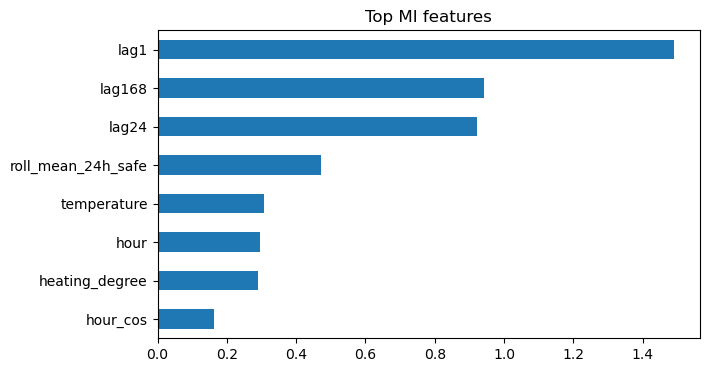

In [17]:
candidate_features = [
    'hour', 'weekday', 'is_weekend',
    'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos',
    'lag1', 'lag24', 'lag168',
    'roll_mean_24h_safe', 'roll_std_24h_safe',
    'temperature', 'heating_degree'
]

fs_df = demand[candidate_features + ['demand']].dropna().copy()
X_fs = fs_df[candidate_features]
y_fs = fs_df['demand']

mi = mutual_info_regression(X_fs, y_fs, random_state=42)
mi_scores = pd.Series(mi, index=candidate_features).sort_values(ascending=False)

# ✏️ TODO 7 — choose how many top features to display
TOP_K = 8

display(mi_scores.head(TOP_K).to_frame('MI score'))
mi_scores.head(TOP_K).sort_values().plot(kind='barh', figsize=(7, 4), title='Top MI features')
plt.show()

### 💬 Questions — instructor notes
1. The exact top feature should be read from the result; lag features are expected to rank strongly.  
2. **No.** Two features can be redundant with each other; univariate MI does not account for all interactions/redundancy.  
3. MI ranking is a **filter** method.


---
# 7. Interactive feature lab — do engineered features improve Random Forest? 🧪

This is not a full forecasting benchmark; it is a **controlled feature-engineering experiment**.

We use a **chronological 80/20 split**, the **same Random Forest hyperparameters** for each selection, and **NRMSE (%)** to compare feature groups. All experiments use the same complete-case rows, so the comparison is fair.


In [20]:
feature_groups = {
    'Calendar': ['hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', 'is_weekend'],
    'Lags': ['lag1', 'lag24', 'lag168'],
    'Rolling': ['roll_mean_24h_safe', 'roll_std_24h_safe'],
    'Weather/domain': ['temperature'],
}

lab_df = demand[['demand'] + sorted(set(sum(feature_groups.values(), [])))].dropna().copy()

def evaluate_groups(selected_groups):
    if isinstance(selected_groups, str):
        selected_groups = [selected_groups]
    selected_groups = list(selected_groups)

    features = []
    for group in selected_groups:
        features.extend(feature_groups[group])
    features = list(dict.fromkeys(features))

    if not features:
        print('Select at least one feature group.')
        return

    split = int(len(lab_df) * 0.8)
    X_train = lab_df[features].iloc[:split]
    X_test = lab_df[features].iloc[split:]
    y_train = lab_df['demand'].iloc[:split]
    y_test = lab_df['demand'].iloc[split:]

    model = RandomForestRegressor(**RF_PARAMS)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    score = nrmse(y_test, pred)

    print('Features:', features)
    print(f'Random Forest NRMSE: {score:.2f}%')
    return score

if WIDGETS_AVAILABLE:
    group_selector = widgets.SelectMultiple(
        options=list(feature_groups.keys()),
        value=('Calendar',),
        description='Groups',
        rows=4
    )
    out = widgets.interactive_output(evaluate_groups, {'selected_groups': group_selector})
    display(group_selector, out)
else:
    evaluate_groups(['Calendar'])


SelectMultiple(description='Groups', index=(0,), options=('Calendar', 'Lags', 'Rolling', 'Weather/domain'), ro…

Output()

### 🧪 Required experiment
Try at least these combinations and record **NRMSE (%)**. Smaller values indicate better predictions.

| Feature groups | NRMSE (%) |
|---|---:|
| Calendar | `...` |
| Lags | `...` |
| Calendar + Lags | `...` |
| Calendar + Lags + Rolling | `...` |
| All groups | `...` |

### 💬 Interpretation
Which group gave the biggest improvement in NRMSE? Did adding **all** features always help? Why might that happen with Random Forest?

**Your answer:**  
`...`


---
# 8. LLM feature-idea challenge 🤖

An LLM can propose ideas quickly, but **you** must decide whether the feature is meaningful and available at prediction time.

Use this prompt with any LLM:

> We have hourly Estonian electricity demand and historical weather data. Suggest three additional features for a demand prediction model. For each feature, explain (1) why it may help, (2) what raw data it needs, and (3) whether it is known at prediction time. Do not propose any feature that directly uses future demand.

Paste three suggestions below and audit them.

| Proposed feature | Why useful? | Available at prediction time? | SAFE / RISKY |
|---|---|---|---|
| `...` | `...` | `...` | `...` |
| `...` | `...` | `...` | `...` |
| `...` | `...` | `...` | `...` |


### ✏️ Implement ONE LLM suggestion

Choose one suggestion that can be built from the data already available in this practical. Add it as a new column.


In [19]:
# ✅ Example solution — one additional safe feature
# Calendar month is known in advance and can capture broad seasonal structure.
demand['month'] = demand.index.month

display(demand[['month']].head())

,month
timestamp,
2022-01-01 00:00:00,1
2022-01-01 01:00:00,1
2022-01-01 02:00:00,1
2022-01-01 03:00:00,1
2022-01-01 04:00:00,1


### 💬 Defend your feature — example answer
Example: **month** captures slow seasonal variation not fully represented by weekday/hour. Calendar month is known for every future timestamp, so there is no availability problem. I would add it to the same chronological evaluation and compare NRMSE (%) against an otherwise identical feature set.


---
# 9. Final checkpoint ✅ — suggested answers

1. A strong answer might keep **lag24 / lag168** because demand has strong temporal autocorrelation and repeating daily/weekly patterns.  
2. A feature leaks information when it uses the target itself, future values, or any data that would not have been available at the forecast origin.  
3. Scaling is typically **not necessary for Random Forest** because threshold-based tree splits depend on feature ordering rather than distances. Scaling can matter for **KNN and other distance-based models**.  
4. Transformation can change distribution shape or relationship structure, while scaling mostly changes numeric range/units.  
5. Extraction creates a new lower-dimensional representation (e.g. PCs); selection keeps a subset of original features.

### One-sentence takeaway
> **Features do not become useful because they are clever; they become useful when they encode a real pattern, are available at prediction time, and improve out-of-sample performance.**
